# Модель оценки стоимости квартир в Астане

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, precision_score, recall_score, roc_auc_score, roc_curve
from scipy import stats

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

## 1. Данные


In [2]:
raw = pd.read_csv('data/merged_df.csv')
print('Размер:', raw.shape)
raw.head(3)

Размер: (18434, 35)


,name,information,address,price,owner,complex_name,house_type,in_pledge,construction_year,ceiling_height,bathroom_info,condition,area,room_count,floor,floor_count,district,complex_class,parking,elevator,schools_within_500m,kindergartens_within_500m,park_within_1km,coordinates,distance_to_center,distance_to_botanical_garden,distance_to_triathlon_park,distance_to_astana_park,distance_to_treatment_facility,distance_to_railway_station_1,distance_to_railway_station_2,distance_to_industrial_zone,kzt_sq_m,last_floor,first_floor
0,"3-комнатная квартира, 77 м², 1/4 этаж","2018 г.п., санузел раздельный, ✅Полноценная 3 ...",Е 496 10,33000000,agent,kemel,monolithic,False,2018,2.500,separate,NaN,77.000,3,1.000,4.000,esil,economy,aboveground,no,0.000,0.000,False,"(51.073887, 71.427446)",6.059,3.704,7.078,9.179,10.063,13.598,8.466,11.385,"428,571.429",False,True
1,"1-комнатная квартира, 40 м², 3/14 этаж","жил. комплекс Jetisu.Lepsi, монолитный дом, 20...",Улы Дала — Ұлы дала,21000000,agent,jetisu.lepsi,monolithic,False,2023,3.000,combined,good,40.000,1,3.000,14.000,esil,comfort,underground,yes,0.000,0.000,False,"(51.08789, 71.469526)",5.267,4.259,5.520,8.361,11.188,12.703,5.137,8.163,"525,000.000",False,False
2,"1-комнатная квартира, 43.8 м², 6/18 этаж","жил. комплекс BURABAY, монолитный дом, 2022 г....",Ж. Нажимеденова 62 — А62,18500000,agent,burabay,monolithic,False,2022,2.700,combined,NaN,43.800,1,6.000,18.000,almaty,economy,underground,yes,0.000,0.000,False,"(51.108635, 71.535381)",7.671,8.341,6.717,9.662,14.427,13.097,0.504,3.686,"422,374.429",False,False


До разделения выборки:
- удаляю `kzt_sq_m` - это `price / area`, то есть утечка таргета;
- удаляю повторные объявления (совпадают все столбцы, кроме текста `information` и продавца `owner`)

In [3]:
raw = raw.drop(columns=['kzt_sq_m'])

cols_for_duplicates = []
for col in raw.columns:
    if col not in ['information', 'owner']:
        cols_for_duplicates.append(col)

print('Полных дубликатов:', raw.duplicated().sum())
print('Повторных объявлений:', raw.duplicated(subset=cols_for_duplicates).sum())

raw = raw.drop_duplicates(subset=cols_for_duplicates).reset_index(drop=True)
print('Размер после удаления:', raw.shape)

Полных дубликатов: 8
Повторных объявлений: 239
Размер после удаления: (18195, 34)


Отделяю тестовую часть (20%). Весь дальнейший анализ - только на train.

In [4]:
train_raw, test_raw = train_test_split(raw, test_size=0.2, random_state=RANDOM_STATE)
train_raw = train_raw.reset_index(drop=True)
test_raw = test_raw.reset_index(drop=True)
print('Train:', train_raw.shape, ' Test:', test_raw.shape)

Train: (14556, 34)  Test: (3639, 34)


## 2. Предобработка

In [5]:
train_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 14556 entries, 0 to 14555
Data columns (total 34 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   name                            14556 non-null  str    
 1   information                     14556 non-null  str    
 2   address                         14556 non-null  str    
 3   price                           14556 non-null  int64  
 4   owner                           14556 non-null  str    
 5   complex_name                    14556 non-null  str    
 6   house_type                      14556 non-null  str    
 7   in_pledge                       14556 non-null  bool   
 8   construction_year               14556 non-null  int64  
 9   ceiling_height                  14556 non-null  float64
 10  bathroom_info                   9767 non-null   str    
 11  condition                       9816 non-null   str    
 12  area                            14556 non-n

In [6]:
print(train_raw.isna().sum()[train_raw.isna().sum() > 0])
print('Дубликатов в train:', train_raw.duplicated().sum())

bathroom_info    4789
condition        4740
dtype: int64
Дубликатов в train: 0


In [7]:
train_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
price,"14,556.000","37,532,088.487","39,817,943.528","4,000,000.000","19,980,000.000","27,000,000.000","40,700,000.000","1,800,000,000.000"
construction_year,"14,556.000","2,014.630",11.461,"1,919.000","2,012.000","2,018.000","2,022.000","2,025.000"
ceiling_height,"14,556.000",2.846,0.179,2.000,2.700,2.800,3.000,4.800
area,"14,556.000",68.829,41.451,11.000,42.000,59.000,82.000,773.300
room_count,"14,556.000",2.149,1.097,1.000,1.000,2.000,3.000,43.000
floor,"14,556.000",6.675,4.378,1.000,3.000,6.000,9.000,41.000
floor_count,"14,556.000",11.471,5.169,1.000,9.000,10.000,14.000,43.000
schools_within_500m,"14,556.000",1.214,2.101,0.000,0.000,0.000,2.000,15.000
kindergartens_within_500m,"14,556.000",0.861,1.854,0.000,0.000,0.000,1.000,15.000
distance_to_center,"14,556.000",5.612,47.743,0.250,2.845,3.960,5.232,"2,565.387"


### 2.1 Пропуски

In [8]:
print(pd.crosstab(train_raw['condition'].isna(), train_raw['bathroom_info'].isna(),
                  rownames=['condition пуст'], colnames=['bathroom_info пуст']))
print()
print((train_raw['price'] / train_raw['area']).groupby(train_raw['condition'].fillna('не указано')).median())

bathroom_info пуст  False  True 
condition пуст                  
False                7970   1846
True                 1797   2943

condition
average      405,405.405
good         494,590.643
rough        440,104.167
не указано   487,604.532
dtype: float64


Пропуски есть только в `condition` и `bathroom_info` (около трети строк). Удалять строки не буду из-за потери трети данных, заполнять модой тоже, тк смешаются с `good`. Пропуск становится отдельной категорией `unknown`

### 2.2 Таргет

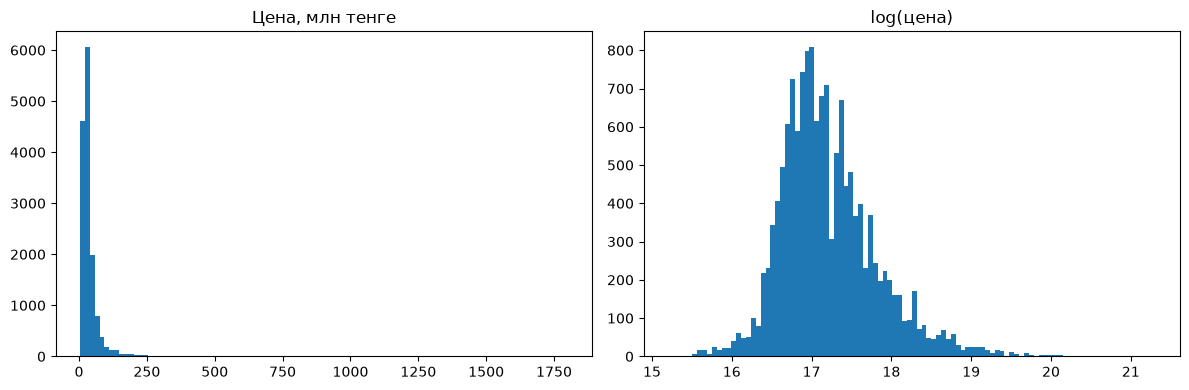

Среднее: 37.5 млн;  медиана: 27.0 млн


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train_raw['price'] / 1e6, bins=100)
axes[0].set_title('Цена, млн тенге')
axes[1].hist(np.log(train_raw['price']), bins=100)
axes[1].set_title('log(цена)')
plt.tight_layout()
plt.show()

print('Среднее:', round(train_raw['price'].mean() / 1e6, 1), 'млн;  медиана:', round(train_raw['price'].median() / 1e6, 1), 'млн')

Распределение цены сильно скошено вправо, после логарифма оно близко к симметричному. Модели обучаю на `log(price)`, прогноз перевожу обратно через `exp`. 

### 2.3 Выбросы

In [10]:
train_raw['price_per_m2'] = train_raw['price'] / train_raw['area']
print(train_raw['price_per_m2'].describe(percentiles=[0.001, 0.01, 0.99, 0.999]))

count      14,556.000
mean      512,651.005
std       171,670.246
min       105,042.017
0.1%      211,667.489
1%        279,366.126
99%     1,111,111.111
99.9%   1,585,109.756
max     6,000,000.000
Name: price_per_m2, dtype: float64


In [11]:
print(train_raw.nlargest(5, 'price_per_m2')[['name', 'price', 'area', 'complex_class', 'district']])
print()
print(train_raw.nsmallest(5, 'price_per_m2')[['name', 'price', 'area', 'complex_class', 'construction_year']])

                                            name       price    area  \
14430   4-комнатная квартира, 300 м², 24/28 этаж  1800000000 300.000   
6507   2-комнатная квартира, 52.9 м², 13/14 этаж   240000000  52.900   
12892    2-комнатная квартира, 49.4 м², 2/5 этаж   185000000  49.400   
434       4-комнатная квартира, 210 м², 5/6 этаж   500000000 210.000   
5059      5-комнатная квартира, 229 м², 2/3 этаж   526477000 229.000   

      complex_class  district  
14430       premium      esil  
6507        economy  saryarka  
12892       economy    almaty  
434         premium    almaty  
5059        premium    almaty  

                                            name     price    area  \
3290  1-комнатная квартира, 38.08 м², 12/12 этаж   4000000  38.080   
3723     2-комнатная квартира, 53 м², 10/10 этаж   7600000  53.000   
6726    1-комнатная квартира, 43.6 м², 5/18 этаж   6500000  43.600   
348     3-комнатная квартира, 122 м², 14/14 этаж  18700000 122.000   
2957    5-комнатная квар

In [12]:
print('Площадь < 15 м²:', (train_raw['area'] < 15).sum())
print('Меньше 8 м² на комнату:', (train_raw['area'] / train_raw['room_count'] < 8).sum())
print(train_raw[train_raw['area'] / train_raw['room_count'] < 8][['name', 'area', 'room_count']])
print()
print('Расстояние до центра > 30 км:', (train_raw['distance_to_center'] > 30).sum())
print(train_raw['distance_to_center'].describe())
print()
print('Год постройки < 1950:', (train_raw['construction_year'] < 1950).sum())
print(train_raw['construction_year'].sort_values().head(5).values)
print()
print(train_raw['district'].value_counts())
print()
print('Этаж больше этажности:', (train_raw['floor'] > train_raw['floor_count']).sum())

Площадь < 15 м²: 19
Меньше 8 м² на комнату: 1
                                         name    area  room_count
2212  43-комнатная квартира, 144 м², 4/5 этаж 144.000          43

Расстояние до центра > 30 км: 17
count   14,556.000
mean         5.612
std         47.743
min          0.250
25%          2.845
50%          3.960
75%          5.232
max      2,565.387
Name: distance_to_center, dtype: float64

Год постройки < 1950: 2
[1919 1941 1957 1957 1959]

district
almaty       4375
nura         3950
esil         3553
saryarka     1778
baikonur      898
Косшы р-н       2
Name: count, dtype: int64

Этаж больше этажности: 0


| Условие | Решение | Причина |
|---|---|---|
| цена м² > 3 млн | удалить | 4-комнатная за 1,8 млрд (6 млн/м²) - ошибка в цене |
| цена м² < 150 тыс. | удалить | ниже любой реальной квартиры в городе |
| площадь < 15 м² | удалить | комнаты, а не квартиры |
| < 8 м² на комнату | удалить | «43 комнаты» на 144 м² - опечатка |
| расстояние до центра > 30 км | удалить | неверно определены координаты, все расстояния ложные |
| год постройки < 1950 | удалить | ошибки ввода (1919, 1941) |
| район «Косшы» | удалить | другой город, 2 наблюдения |
| потолки 2.0 м или > 4 м | оставить | редко, но возможно |

Выбросы удаляю только из train. Из теста строки по цене не удаляю: для новой квартиры цена неизвестна, поэтому тест должен оставаться таким, как реальные данные. Ошибочные координаты и год в любых данных исправляются в `prepare_features` без использования цены.

In [13]:
n_before = len(train_raw)

bad_rows = (
    (train_raw['price_per_m2'] > 3_000_000) |
    (train_raw['price_per_m2'] < 150_000) |
    (train_raw['area'] < 15) |
    (train_raw['area'] / train_raw['room_count'] < 8) |
    (train_raw['distance_to_center'] > 30) |
    (train_raw['construction_year'] < 1950) |
    (train_raw['district'] == 'Косшы р-н')
)

train = train_raw[~bad_rows].reset_index(drop=True)
print('Удалено строк:', n_before - len(train), f'({(n_before - len(train)) / n_before:.2%})')
print('Train после чистки:', train.shape)

Удалено строк: 47 (0.32%)
Train после чистки: (14509, 35)


### 2.4 Признаки

- `coordinates` → `lat`, `lon`;
- ошибочные координаты (> 30 км от центра) → медианы района по train;
- год постройки ограничен снизу 1950;
- пропуски в `condition`, `bathroom_info` → `unknown`;
- `floor_ratio` = этаж / этажность;
- `complex_name`: отдельная категория только для ЖК с ≥ 15 объявлениями в train, остальные → `other` (иначе ~1000 столбцов с 1-2 наблюдениями).

In [14]:
distance_cols = ['distance_to_center', 'distance_to_botanical_garden', 'distance_to_triathlon_park',
                 'distance_to_astana_park', 'distance_to_treatment_facility', 'distance_to_railway_station_1',
                 'distance_to_railway_station_2', 'distance_to_industrial_zone']


def split_coordinates(data):
    coords = data['coordinates'].str.strip('()').str.split(',', expand=True)
    data['lat'] = coords[0].astype(float)
    data['lon'] = coords[1].astype(float)
    return data


train = split_coordinates(train)
district_medians = train.groupby('district')[distance_cols + ['lat', 'lon']].median()
city_medians = train[distance_cols + ['lat', 'lon']].median()

complex_counts = train['complex_name'].value_counts()
frequent_complexes = list(complex_counts[complex_counts >= 15].index)
print('ЖК с отдельной категорией:', len(frequent_complexes))
print('Доля train в этих ЖК:', round(train['complex_name'].isin(frequent_complexes).mean(), 3))


def prepare_features(data):
    data = data.copy()
    data = split_coordinates(data)

    wrong_location = data['distance_to_center'] > 30
    for i in data[wrong_location].index:
        district = data.loc[i, 'district']
        for col in distance_cols + ['lat', 'lon']:
            if district in district_medians.index:
                data.loc[i, col] = district_medians.loc[district, col]
            else:
                data.loc[i, col] = city_medians[col]

    data['construction_year'] = data['construction_year'].clip(lower=1950)
    data['condition'] = data['condition'].fillna('unknown')
    data['bathroom_info'] = data['bathroom_info'].fillna('unknown')
    data['floor_ratio'] = data['floor'] / data['floor_count']

    data['complex_group'] = data['complex_name']
    data.loc[~data['complex_name'].isin(frequent_complexes), 'complex_group'] = 'other'

    for col in ['in_pledge', 'park_within_1km', 'last_floor', 'first_floor']:
        data[col] = data[col].astype(int)
    return data


train = prepare_features(train)
test = prepare_features(test_raw)
print(train.shape, test.shape)

ЖК с отдельной категорией: 290
Доля train в этих ЖК: 0.702
(14509, 39) (3639, 38)


Категориальные признаки - `OneHotEncoder` (`handle_unknown='ignore'` на случай новых районов и ЖК), числовые - `StandardScaler` (нужно для линейных моделей, KMeans и PCA). Обучаются только на train. Текстовые поля `name`, `information`, `address` не использую: их содержание уже есть в отдельных столбцах.

In [15]:
numeric_features = ['area', 'room_count', 'floor', 'floor_count', 'floor_ratio', 'construction_year',
                    'ceiling_height', 'schools_within_500m', 'kindergartens_within_500m',
                    'in_pledge', 'park_within_1km', 'last_floor', 'first_floor', 'lat', 'lon'] + distance_cols

categorical_features = ['owner', 'house_type', 'bathroom_info', 'condition', 'district',
                        'complex_class', 'parking', 'elevator', 'complex_group']

encoder = OneHotEncoder(handle_unknown='ignore')
encoder.fit(train[categorical_features])

scaler = StandardScaler()
scaler.fit(train[numeric_features])


def make_X(data):
    X_num = pd.DataFrame(scaler.transform(data[numeric_features]), columns=numeric_features)
    X_cat = pd.DataFrame(encoder.transform(data[categorical_features]).toarray(),
                         columns=encoder.get_feature_names_out(categorical_features))
    return pd.concat([X_num, X_cat], axis=1)


X_train = make_X(train)
X_test = make_X(test)
y_train = np.log(train['price'].values)
y_test = np.log(test['price'].values)
price_train = train['price'].values
price_test = test['price'].values

print('X_train:', X_train.shape, ' X_test:', X_test.shape)

X_train: (14509, 341)  X_test: (3639, 341)


## 3. Метрика

Ошибка 3 млн на квартире за 25 млн - это 12%, на квартире за 150 млн - 2%. Для агентства это разные ошибки: комиссия считается в процентах от цены, и клиент тоже оценивает промах относительно цены. RMSE и MAE считают ошибку в тенге, поэтому несколько квартир за сотни миллионов перевешивают тысячи обычных.

Основная метрика - **MAPE** (средняя абсолютная ошибка в процентах от цены). Дополнительно смотрю долю квартир с ошибкой ≤ 10%. RMSE - для справки.

In [16]:
def mape(price_true, price_pred):
    return np.mean(np.abs(price_true - price_pred) / price_true) * 100


def share_within_10(price_true, price_pred):
    return np.mean(np.abs(price_true - price_pred) / price_true <= 0.10) * 100


print('3 млн на квартире 25 млн:', mape(np.array([25e6]), np.array([28e6])), '%')
print('3 млн на квартире 150 млн:', mape(np.array([150e6]), np.array([153e6])), '%')

3 млн на квартире 25 млн: 12.0 %
3 млн на квартире 150 млн: 2.0 %


## 4. Сравнение моделей



In [17]:
ridge_grid = GridSearchCV(Ridge(), {'alpha': [0.1, 1, 3, 10, 30]},
                          cv=5, scoring='neg_mean_absolute_error')
ridge_grid.fit(X_train, y_train)
print('Ridge:', ridge_grid.best_params_)

tree_grid = GridSearchCV(DecisionTreeRegressor(random_state=RANDOM_STATE),
                         {'max_depth': [6, 8, 10, 12, 15], 'min_samples_leaf': [3, 5, 10]},
                         cv=5, scoring='neg_mean_absolute_error')
tree_grid.fit(X_train, y_train)
print('Decision Tree:', tree_grid.best_params_)

forest_grid = GridSearchCV(RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
                           {'max_features': [0.3, 0.5], 'min_samples_leaf': [1, 3]},
                           cv=3, scoring='neg_mean_absolute_error')
forest_grid.fit(X_train, y_train)
print('Random Forest:', forest_grid.best_params_)

Ridge: {'alpha': 1}
Decision Tree: {'max_depth': 12, 'min_samples_leaf': 5}
Random Forest: {'max_features': 0.3, 'min_samples_leaf': 1}


Кросс-валидация на одних и тех же 5 фолдах для всех моделей. MAPE считаю в тенге, поэтому цикл по `KFold` написан вручную. Out-of-fold прогнозы сохраняю для доверительных интервалов и сравнения моделей.

In [18]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(**ridge_grid.best_params_),
    'Decision Tree': DecisionTreeRegressor(random_state=RANDOM_STATE, **tree_grid.best_params_),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1,
                                           **forest_grid.best_params_),
}

kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(kfold.split(X_train))


def rule_of_thumb_predict(train_part, other_part):
    ppm_by_district = (train_part['price'] / train_part['area']).groupby(train_part['district']).median()
    city_ppm = (train_part['price'] / train_part['area']).median()
    ppm = other_part['district'].map(ppm_by_district).fillna(city_ppm)
    return ppm.values * other_part['area'].values


def cross_validate(model, X, y, price):
    fold_mapes = []
    oof_pred = np.zeros(len(y))
    for train_idx, valid_idx in folds:
        model.fit(X.iloc[train_idx], y[train_idx])
        pred = np.exp(model.predict(X.iloc[valid_idx]))
        oof_pred[valid_idx] = pred
        fold_mapes.append(mape(price[valid_idx], pred))
    return fold_mapes, oof_pred


fold_results = {}
oof_predictions = {}

fold_mapes = []
oof_pred = np.zeros(len(train))
for train_idx, valid_idx in folds:
    pred = rule_of_thumb_predict(train.iloc[train_idx], train.iloc[valid_idx])
    oof_pred[valid_idx] = pred
    fold_mapes.append(mape(price_train[valid_idx], pred))
fold_results['Правило: цена м² района × площадь'] = fold_mapes
oof_predictions['Правило: цена м² района × площадь'] = oof_pred

for name, model in models.items():
    fold_mapes, oof_pred = cross_validate(model, X_train, y_train, price_train)
    fold_results[name] = fold_mapes
    oof_predictions[name] = oof_pred

pd.DataFrame(fold_results, index=[f'фолд {i + 1}' for i in range(5)]).T.round(2)

,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5
Правило: цена м² района × площадь,18.090,17.990,18.370,18.250,18.090
Linear Regression,13.870,14.250,14.050,14.390,14.140
Ridge,13.870,14.210,14.060,14.370,14.140
Decision Tree,13.860,14.210,13.820,14.030,14.290
Random Forest,10.090,10.240,10.050,10.320,10.290


95% доверительный интервал для MAPE: MAPE - среднее из ~14,5 тыс. ошибок отдельных квартир, поэтому по ЦПТ интервал = среднее ± 1.96 · std / √n.

In [19]:
def mean_ci(values):
    mean = np.mean(values)
    se = np.std(values, ddof=1) / np.sqrt(len(values))
    return mean, mean - 1.96 * se, mean + 1.96 * se


ape = {}
for name in oof_predictions:
    ape[name] = np.abs(price_train - oof_predictions[name]) / price_train * 100

rows = []
for name in oof_predictions:
    mean, low, high = mean_ci(ape[name])
    rows.append({
        'Модель': name,
        'MAPE (CV), %': mean,
        '95% ДИ': f'[{low:.2f}; {high:.2f}]',
        'std по фолдам': np.std(fold_results[name], ddof=1),
        'Доля с ошибкой ≤10%': share_within_10(price_train, oof_predictions[name]),
        'RMSE, млн': np.sqrt(np.mean((price_train - oof_predictions[name]) ** 2)) / 1e6,
    })
cv_table = pd.DataFrame(rows).set_index('Модель')
cv_table.round(2)

,"MAPE (CV), %",95% ДИ,std по фолдам,Доля с ошибкой ≤10%,"RMSE, млн"
Модель,,,,,
Правило: цена м² района × площадь,18.160,[17.89; 18.42],0.150,37.510,21.980
Linear Regression,14.140,[13.79; 14.50],0.200,49.330,70.210
Ridge,14.130,[13.77; 14.49],0.180,49.390,70.720
Decision Tree,14.040,[13.80; 14.28],0.210,49.570,17.120
Random Forest,10.200,[10.02; 10.37],0.120,62.440,13.540


Значимость разницы. H0: средние ошибки двух моделей равны, α = 0.05. Сравниваю попарно на одних и тех же квартирах: разница ошибок для каждой квартиры, 95% ДИ для средней разницы и p-value (z-критерий). Ошибки внутри одного фолда не полностью независимы, поэтому дополнительно смотрю, на скольких фолдах выигрывает модель.

In [20]:
def compare_models(name_a, name_b):
    diff = ape[name_a] - ape[name_b]
    mean, low, high = mean_ci(diff)
    se = np.std(diff, ddof=1) / np.sqrt(len(diff))
    p_value = 2 * stats.norm.sf(abs(mean / se))
    folds_won = sum(np.array(fold_results[name_b]) < np.array(fold_results[name_a]))
    return {'Сравнение': f'{name_a}  vs  {name_b}',
            'Разница MAPE, п.п.': mean,
            '95% ДИ разницы': f'[{low:.2f}; {high:.2f}]',
            'p-value': p_value,
            'Значимо (α=0.05)': 'да' if (low > 0 or high < 0) else 'нет',
            'Фолдов, где 2-я лучше': f'{folds_won} из 5'}


pairs = [('Правило: цена м² района × площадь', 'Linear Regression'),
         ('Linear Regression', 'Ridge'),
         ('Ridge', 'Decision Tree'),
         ('Ridge', 'Random Forest'),
         ('Decision Tree', 'Random Forest')]

comparison = pd.DataFrame([compare_models(a, b) for a, b in pairs])
comparison

,Сравнение,"Разница MAPE, п.п.",95% ДИ разницы,p-value,Значимо (α=0.05),"Фолдов, где 2-я лучше"
0,Правило: цена м² района × площадь vs Linear ...,4.014,[3.62; 4.41],0.000,да,5 из 5
1,Linear Regression vs Ridge,0.014,[0.00; 0.02],0.007,да,3 из 5
2,Ridge vs Decision Tree,0.085,[-0.28; 0.45],0.647,нет,4 из 5
3,Ridge vs Random Forest,3.931,[3.60; 4.26],0.000,да,5 из 5
4,Decision Tree vs Random Forest,3.846,[3.66; 4.04],0.000,да,5 из 5


Выводы:
- все модели значимо лучше правила «цена м² района × площадь» (18,2%);
- Linear Regression и Ridge - 14,1%. Разница формально значима (p ≈ 0.007), но составляет 0,01 п.п., практического значения не имеет: при n ≈ 14,5 тыс. значимыми становятся даже очень маленькие различия. Регуляризация почти не помогает, так как наблюдений намного больше, чем признаков;
- Decision Tree не отличается от Ridge значимо (ДИ разницы содержит 0, p = 0.65);
- Random Forest значимо лучше всех: 10,2% (ДИ 10,0-10,4), выигрыш около 4 п.п. на всех 5 фолдах, наименьший разброс по фолдам;
- большой RMSE у линейных моделей - из-за нескольких дорогих квартир, на которых прогноз после `exp` сильно завышается.

Финальная модель - Random Forest.

## 5. Проверка на тесте

In [21]:
best_model = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1,
                                   **forest_grid.best_params_)
best_model.fit(X_train, y_train)
pred_test = np.exp(best_model.predict(X_test))

ape_test = np.abs(price_test - pred_test) / price_test * 100
mean, low, high = mean_ci(ape_test)
print(f'MAPE на тесте: {mean:.2f}%  (95% ДИ: {low:.2f}% – {high:.2f}%)')
print(f'Медианная ошибка: {np.median(ape_test):.2f}%')
print(f'Доля квартир с ошибкой ≤ 10%: {share_within_10(price_test, pred_test):.1f}%')
print(f'Доля квартир с ошибкой > 20%: {np.mean(ape_test > 20) * 100:.1f}%')

MAPE на тесте: 9.69%  (95% ДИ: 9.39% – 10.00%)
Медианная ошибка: 7.05%
Доля квартир с ошибкой ≤ 10%: 63.9%
Доля квартир с ошибкой > 20%: 11.5%


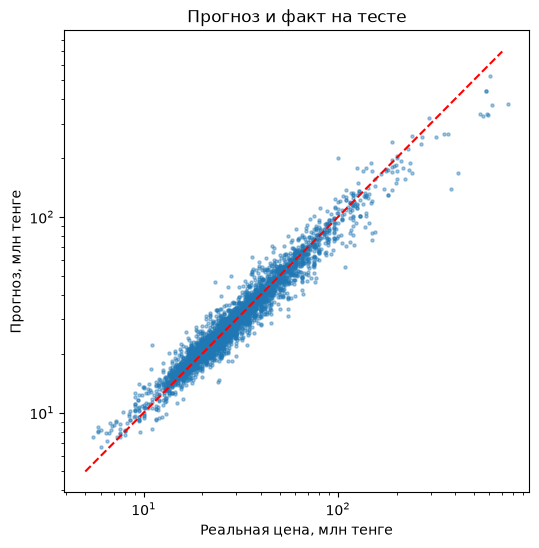

In [22]:
plt.figure(figsize=(6, 6))
plt.scatter(price_test / 1e6, pred_test / 1e6, s=5, alpha=0.4)
plt.plot([5, 700], [5, 700], 'r--')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Реальная цена, млн тенге')
plt.ylabel('Прогноз, млн тенге')
plt.title('Прогноз и факт на тесте')
plt.show()

## 6. Сегменты рынка

Кластеризую KMeans по характеристикам квартиры и дома (без цены): площадь, комнаты, год, потолки, этажность, расстояние до центра, класс ЖК (эконом=0 … премиум=3). Признаки стандартизованы.

k=2: inertia=77,621
k=3: inertia=64,157
k=4: inertia=54,872
k=5: inertia=49,576
k=6: inertia=45,133
k=7: inertia=41,834
k=8: inertia=39,296
k=9: inertia=37,151


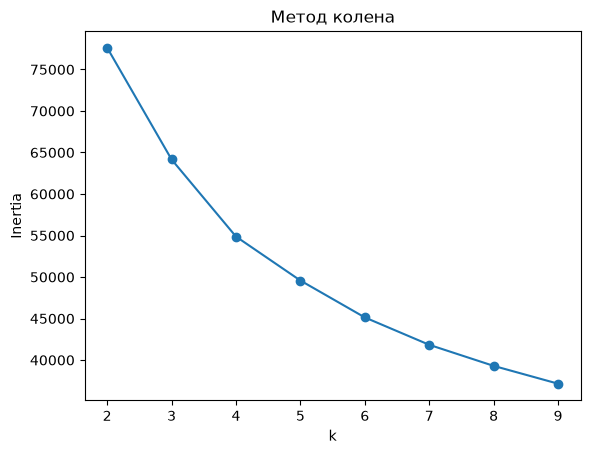

In [23]:
class_rank = {'economy': 0, 'comfort': 1, 'business': 2, 'premium': 3}
train['class_rank'] = train['complex_class'].map(class_rank)
test['class_rank'] = test['complex_class'].map(class_rank)

segment_features = ['area', 'room_count', 'construction_year', 'ceiling_height',
                    'floor_count', 'distance_to_center', 'class_rank']

segment_scaler = StandardScaler()
S_train = segment_scaler.fit_transform(train[segment_features])
S_test = segment_scaler.transform(test[segment_features])

inertias = []
k_values = range(2, 10)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(S_train)
    inertias.append(km.inertia_)

for k, inertia in zip(k_values, inertias):
    print(f'k={k}: inertia={inertia:,.0f}')

plt.plot(list(k_values), inertias, marker='o')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Метод колена')
plt.show()

Чёткого колена нет: до k = 5 inertia падает на 10-17% за шаг, дальше - на 7-9%. Беру k = 5. При k = 4 старый фонд сливается с остальными эконом-квартирами.

In [24]:
N_SEGMENTS = 5
kmeans = KMeans(n_clusters=N_SEGMENTS, random_state=RANDOM_STATE, n_init=10)
kmeans.fit(S_train)
train['segment'] = kmeans.labels_
test['segment'] = kmeans.predict(S_test)

train['price_per_m2'] = train['price'] / train['area']
segment_profile = train.groupby('segment').agg(
    count=('price', 'count'),
    median_price_mln=('price', 'median'),
    median_price_m2_ths=('price_per_m2', 'median'),
    median_area=('area', 'median'),
    median_rooms=('room_count', 'median'),
    median_year=('construction_year', 'median'),
    median_ceiling=('ceiling_height', 'median'),
    median_floors=('floor_count', 'median'),
    median_dist_center=('distance_to_center', 'median'),
    mean_class_rank=('class_rank', 'mean'),
)
segment_profile['median_price_mln'] = segment_profile['median_price_mln'] / 1e6
segment_profile['median_price_m2_ths'] = segment_profile['median_price_m2_ths'] / 1e3
segment_profile['share_%'] = segment_profile['count'] / len(train) * 100
segment_profile.round(2)

,count,median_price_mln,median_price_m2_ths,median_area,median_rooms,median_year,median_ceiling,median_floors,median_dist_center,mean_class_rank,share_%
segment,,,,,,,,,,,
0,3315,32.500,448.430,72.000,3.000,"2,015.000",2.700,12.000,3.830,0.550,22.850
1,1106,18.500,386.580,50.000,2.000,"1,982.000",2.700,5.000,5.030,0.000,7.620
2,2000,77.000,631.170,125.000,4.000,"2,018.000",3.000,10.000,2.530,2.150,13.780
3,4624,28.000,550.000,51.300,2.000,"2,022.000",3.000,12.000,3.490,1.310,31.870
4,3464,18.500,431.600,41.800,1.000,"2,019.000",2.700,9.000,5.690,0.490,23.870


In [25]:
print(pd.crosstab(train['segment'], train['complex_class'], normalize='index').round(2))
print()
print(pd.crosstab(train['segment'], train['district'], normalize='index').round(2))

complex_class  business  comfort  economy  premium
segment                                           
0                 0.060    0.430    0.510    0.000
1                 0.000    0.000    1.000    0.000
2                 0.520    0.150    0.010    0.320
3                 0.250    0.700    0.010    0.040
4                 0.030    0.440    0.540    0.000

district  almaty  baikonur  esil  nura  saryarka
segment                                         
0          0.290     0.100 0.280 0.240     0.090
1          0.370     0.230 0.010 0.000     0.390
2          0.250     0.050 0.400 0.250     0.050
3          0.190     0.020 0.280 0.460     0.050
4          0.470     0.030 0.150 0.150     0.200


| Сегмент | Доля | Описание | Медиана цены м² |
|---|---|---|---|
| 1 - старый фонд | 8% | дома ~1980 г., 5 этажей, только эконом; Сарыарка, Алматы, Байконур | ~387 тыс. |
| 4 - компактные на окраинах | 24% | 1 комната, ~42 м², дома ~2019 г., ~5,7 км от центра | ~432 тыс. |
| 0 - семейные массовые | 23% | 3 комнаты, ~72 м², дома ~2015 г., эконом/комфорт, потолки 2,7 м | ~448 тыс. |
| 3 - новостройки комфорт+ | 32% | 2 комнаты, ~51 м², дома ~2022 г., потолки 3 м, комфорт/бизнес; Нура, Есиль | ~550 тыс. |
| 2 - большие бизнес/премиум | 14% | 4 комнаты, ~125 м², потолки 3 м, 2,5 км от центра, 84% бизнес/премиум | ~631 тыс. |

Такие группы не задаются ни одним исходным столбцом: например, «новостройки комфорт+» включают и комфорт, и бизнес-класс.

In [26]:
segment_names = {0: 'семейные массовые', 1: 'старый фонд', 2: 'большие бизнес/премиум',
                 3: 'новостройки комфорт+', 4: 'компактные на окраинах'}
train['segment_name'] = train['segment'].map(segment_names)
test['segment_name'] = test['segment'].map(segment_names)

Проверка, улучшает ли сегмент модель цены: добавляю его как one-hot признак и повторяю кросс-валидацию для Ridge и Random Forest.

In [27]:
segment_encoder = OneHotEncoder(handle_unknown='ignore')
segment_encoder.fit(train[['segment']])


def add_segment(X, data):
    seg = pd.DataFrame(segment_encoder.transform(data[['segment']]).toarray(),
                       columns=segment_encoder.get_feature_names_out(['segment']))
    return pd.concat([X, seg], axis=1)


X_train_seg = add_segment(X_train, train)

for name in ['Ridge', 'Random Forest']:
    fold_mapes, oof_pred = cross_validate(models[name], X_train_seg, y_train, price_train)
    fold_results[name + ' + сегмент'] = fold_mapes
    oof_predictions[name + ' + сегмент'] = oof_pred
    ape[name + ' + сегмент'] = np.abs(price_train - oof_pred) / price_train * 100

segment_comparison = pd.DataFrame([compare_models('Ridge', 'Ridge + сегмент'),
                                   compare_models('Random Forest', 'Random Forest + сегмент')])
segment_comparison

,Сравнение,"Разница MAPE, п.п.",95% ДИ разницы,p-value,Значимо (α=0.05),"Фолдов, где 2-я лучше"
0,Ridge vs Ridge + сегмент,0.067,[0.01; 0.12],0.016,да,5 из 5
1,Random Forest vs Random Forest + сегмент,-0.010,[-0.05; 0.03],0.647,нет,2 из 5


- Ridge: сегмент снижает ошибку на 0,07 п.п. (ДИ 0,01-0,12, 5 из 5 фолдов) - значимо, но мало. Линейная модель сама не комбинирует признаки, а сегмент даёт ей готовую комбинацию.
- Random Forest: разница незначима (-0,01 п.п., ДИ от -0,05 до 0,03, p = 0.65, лучше на 2 фолдах из 5). Деревья сами находят эти сочетания признаков.

В финальную модель сегмент не добавляю, использую его для описания рынка и анализа ошибок.

### PCA

In [28]:
pca = PCA(n_components=2)
P_train = pca.fit_transform(S_train)
print('Доля объяснённой дисперсии:', pca.explained_variance_ratio_.round(3),
      ' сумма:', pca.explained_variance_ratio_.sum().round(3))

loadings = pd.DataFrame(pca.components_.T, index=segment_features, columns=['PC1', 'PC2'])
loadings.round(2)

Доля объяснённой дисперсии: [0.398 0.218]  сумма: 0.615


,PC1,PC2
area,0.450,0.450
room_count,0.390,0.550
construction_year,0.230,-0.550
ceiling_height,0.430,-0.250
floor_count,0.240,-0.310
distance_to_center,-0.360,0.080
class_rank,0.470,-0.170


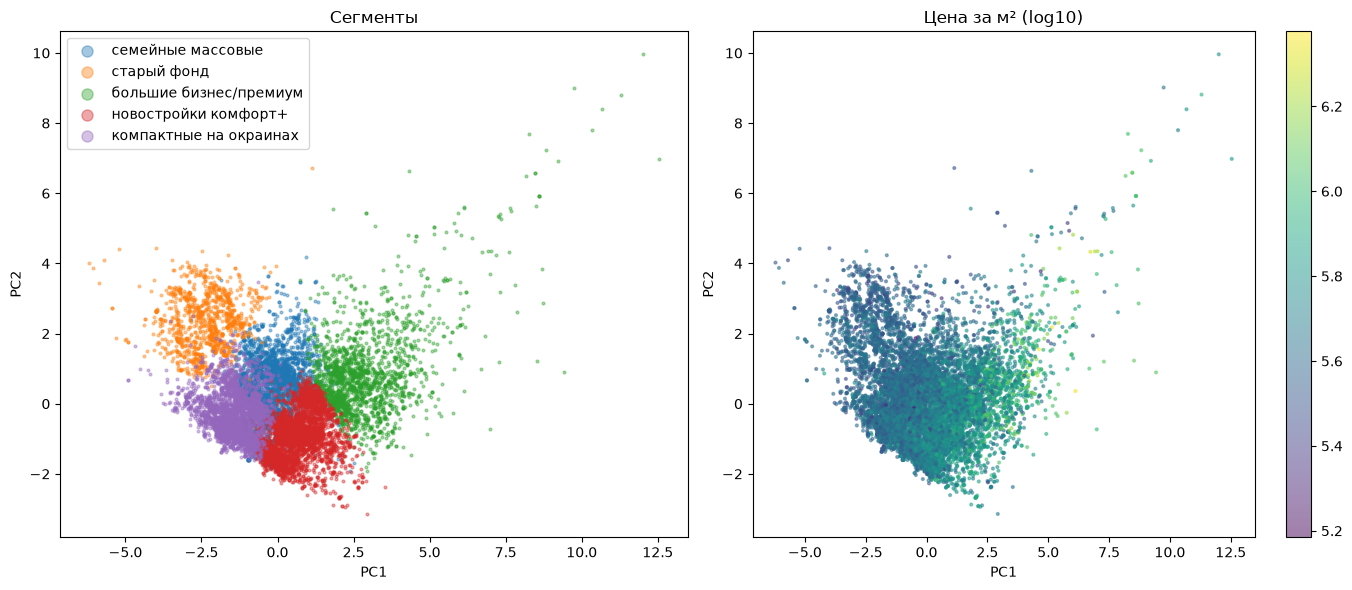

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for seg in range(N_SEGMENTS):
    part = train['segment'] == seg
    axes[0].scatter(P_train[part, 0], P_train[part, 1], s=4, alpha=0.4, label=segment_names[seg])
axes[0].set_title('Сегменты')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend(markerscale=4)

points = axes[1].scatter(P_train[:, 0], P_train[:, 1], c=np.log10(train['price_per_m2']), s=4, alpha=0.5, cmap='viridis')
axes[1].set_title('Цена за м² (log10)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
plt.colorbar(points, ax=axes[1])
plt.tight_layout()
plt.show()

Две компоненты объясняют 62% дисперсии.
- PC1 (40%) - «уровень жилья»: с плюсом класс ЖК (0.47), площадь (0.45), потолки (0.43), комнаты (0.39), с минусом расстояние до центра (-0.36). Цена м² растёт вдоль PC1 (правый график).
- PC2 (22%) - «размер против новизны»: с плюсом комнаты (0.55) и площадь (0.45), с минусом год постройки (-0.55), этажность (-0.31), потолки (-0.25). Вверху - большие квартиры в старых невысоких домах, внизу - компактные в новых высотках.

Сегменты разделены и в этом пространстве. Сегмент «большие бизнес/премиум» сильно растянут вправо: эти квартиры мало похожи друг на друга.

## 7. Факторы цены

Ridge: таргет - `log(price)`, числовые признаки стандартизованы, поэтому `exp(коэф) - 1` - изменение цены в % при росте признака на 1 std, для категорий - отличие от среднего. Random Forest: `feature_importances_`, суммированные по one-hot столбцам каждого признака.

In [30]:
ridge_final = Ridge(**ridge_grid.best_params_)
ridge_final.fit(X_train, y_train)

ridge_effects = pd.DataFrame({'признак': X_train.columns,
                              'коэф': ridge_final.coef_,
                              'эффект, %': (np.exp(ridge_final.coef_) - 1) * 100})
print(ridge_effects[ridge_effects['признак'].isin(numeric_features)]
      .sort_values('эффект, %', key=abs, ascending=False).head(12).round(2).to_string(index=False))

                       признак   коэф  эффект, %
                          area  0.210     23.650
                    room_count  0.200     22.640
  distance_to_botanical_garden -0.180    -16.690
distance_to_treatment_facility  0.140     15.370
       distance_to_astana_park -0.140    -13.050
 distance_to_railway_station_1  0.110     11.700
   distance_to_industrial_zone  0.090      9.740
                           lat  0.090      9.240
             construction_year  0.060      6.430
 distance_to_railway_station_2  0.060      6.070
                ceiling_height  0.040      3.730
                           lon  0.030      3.270


In [31]:
not_complex = ~ridge_effects['признак'].str.startswith('complex_group') & ~ridge_effects['признак'].isin(numeric_features)
print(ridge_effects[not_complex].sort_values('эффект, %', key=abs, ascending=False).head(12).round(2).to_string(index=False))

                признак   коэф  эффект, %
  complex_class_premium  0.210     23.570
  complex_class_economy -0.130    -12.600
        condition_rough -0.120    -11.390
  complex_class_comfort -0.110    -10.070
        district_almaty  0.090      9.450
         condition_good  0.080      7.860
bathroom_info_2 or more  0.050      5.470
           elevator_yes  0.050      5.440
            elevator_no -0.050     -5.160
          district_esil -0.050     -4.880
      condition_unknown  0.050      4.870
      district_baikonur -0.050     -4.430


In [32]:
rf_importance = pd.Series(best_model.feature_importances_, index=X_train.columns)
grouped_importance = {}
for col in X_train.columns:
    original = col
    for cat in categorical_features:
        if col.startswith(cat + '_'):
            original = cat
    grouped_importance[original] = grouped_importance.get(original, 0) + rf_importance[col]
grouped_importance = pd.Series(grouped_importance).sort_values(ascending=False)

# сила признака в Ridge: |коэф| для числовых, max − min коэффициентов категорий для категориальных
ridge_strength = {}
for col in numeric_features:
    ridge_strength[col] = abs(ridge_effects.loc[ridge_effects['признак'] == col, 'коэф'].values[0])
for cat in categorical_features:
    coefs = ridge_effects[ridge_effects['признак'].str.startswith(cat + '_')]['коэф']
    ridge_strength[cat] = coefs.max() - coefs.min()
ridge_strength = pd.Series(ridge_strength)

factors = pd.DataFrame({'RF важность': grouped_importance,
                        'RF ранг': grouped_importance.rank(ascending=False),
                        'Ridge сила': ridge_strength,
                        'Ridge ранг': ridge_strength.rank(ascending=False)})
factors.sort_values('RF ранг').head(15).round(3)

,RF важность,RF ранг,Ridge сила,Ridge ранг
area,0.424,1.000,0.212,3.000
room_count,0.201,2.000,0.204,4.000
complex_class,0.073,3.000,0.346,2.000
bathroom_info,0.055,4.000,0.089,13.000
distance_to_botanical_garden,0.041,5.000,0.183,6.000
distance_to_center,0.041,6.000,0.001,32.000
ceiling_height,0.034,7.000,0.037,19.000
construction_year,0.015,8.000,0.062,15.000
elevator,0.011,9.000,0.106,11.000
complex_group,0.009,10.000,0.945,1.000


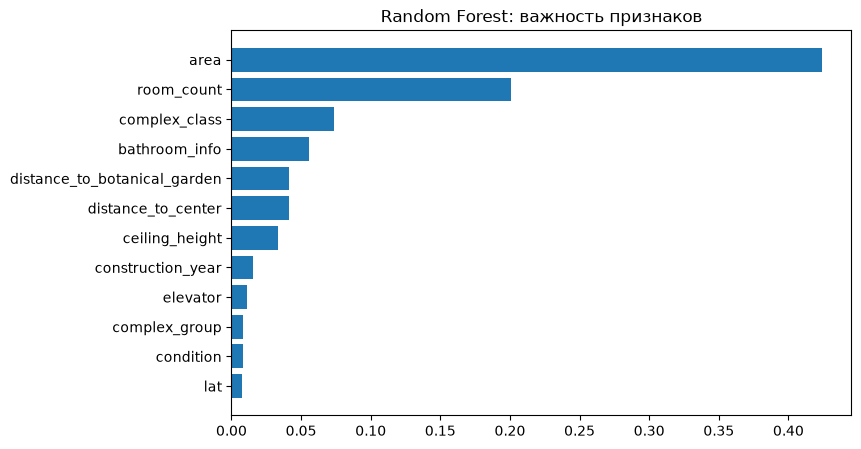

In [33]:
top = grouped_importance.head(12)[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top.index, top.values)
plt.title('Random Forest: важность признаков')
plt.show()

В обеих моделях главные факторы - площадь и число комнат, класс ЖК, расположение и высота потолков. По Ridge: +1 std площади ≈ +24% к цене, премиум ≈ +24%, эконом ≈ -13%, черновая отделка ≈ -11%, хорошее состояние ≈ +8%.

Расхождения:
1. ЖК (`complex_group`) - первое место в Ridge, десятое в RF. Ridge учитывает престиж дома только через отдельный коэффициент ЖК, а RF получает ту же информацию из координат, расстояний и класса. К тому же в RF важность делится между 290 столбцами ЖК с небольшим числом наблюдений в каждом.
2. Расстояние до центра - шестое место в RF и почти ноль в Ridge. Расстояния и координаты сильно коррелируют между собой, и Ridge распределяет эффект между ними произвольно (отсюда, например, +15% у `distance_to_treatment_facility`). Поэтому интерпретирую расположение в целом, а не отдельные расстояния.
3. Санузел - четвёртое место в RF, тринадцатое в Ridge. «2 санузла и более» уточняет цену внутри больших квартир (нелинейный эффект); в линейной модели это уже объяснено площадью и комнатами.
4. RF показывает только силу влияния, Ridge - и направление, но в предположении линейности.

## 8. Бинарная классификация

Задача: попадает ли цена м² квартиры в верхние 25% рынка (порог - 75-й перцентиль цены м² в train). Агентству это нужно, чтобы ещё до оценки решить, вести ли квартиру через премиальный канал (опытный брокер, продвижение, состоятельные покупатели). Признаки те же, что в регрессии, цены среди них нет.

In [34]:
premium_threshold = train['price_per_m2'].quantile(0.75)
print(f'Порог: {premium_threshold:,.0f} тенге/м²')

target_train = (train['price_per_m2'] >= premium_threshold).astype(int).values
target_test = (test['price'] / test['area'] >= premium_threshold).astype(int).values
print('Доля класса 1 в train:', target_train.mean().round(3), ' в test:', target_test.mean().round(3))

Порог: 578,125 тенге/м²
Доля класса 1 в train: 0.25  в test: 0.252


In [35]:
# ROC-AUC каждого признака по отдельности
single_auc = {}
for col in X_train.columns:
    auc = roc_auc_score(target_train, X_train[col])
    single_auc[col] = max(auc, 1 - auc)
single_auc = pd.Series(single_auc).sort_values(ascending=False)
print(single_auc.head(5).round(3))

distance_to_botanical_garden   0.786
ceiling_height                 0.760
distance_to_center             0.749
complex_class_economy          0.686
lat                            0.681
dtype: float64


Лучший одиночный признак даёт ROC-AUC 0.79, так что таргет из одного признака не восстанавливается.

Модель - логистическая регрессия. Вероятности для подбора порога - out-of-fold на тех же 5 фолдах.

In [36]:
log_reg = LogisticRegression(max_iter=2000, C=1.0)

oof_proba = np.zeros(len(train))
for train_idx, valid_idx in folds:
    log_reg.fit(X_train.iloc[train_idx], target_train[train_idx])
    oof_proba[valid_idx] = log_reg.predict_proba(X_train.iloc[valid_idx])[:, 1]
print('ROC-AUC (CV):', round(roc_auc_score(target_train, oof_proba), 3))

ROC-AUC (CV): 0.921


Стоимость ошибок:
- FP - обычная квартира попала в премиальный канал: лишние расходы на продвижение и время брокера - 1;
- FN - премиальная квартира продаётся как обычная: дольше или дешевле, агентство теряет часть комиссии - 3.

Соотношение 3:1 - допущение, ниже показано, как от него зависит порог. Выбираю порог с минимальной суммой 1·FP + 3·FN.

Порог: 0.3
Стоимость при 0.5: 4243  при выбранном пороге: 3245  (24% меньше)


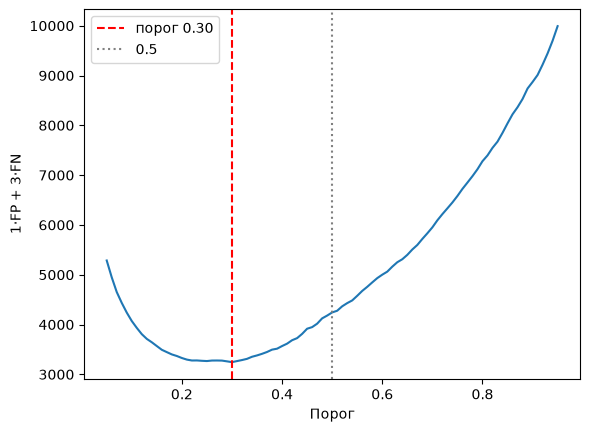

In [37]:
COST_FP = 1
COST_FN = 3

thresholds = np.arange(0.05, 0.96, 0.01)
costs = []
for t in thresholds:
    pred = (oof_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(target_train, pred).ravel()
    costs.append(COST_FP * fp + COST_FN * fn)

best_threshold = thresholds[np.argmin(costs)]
print('Порог:', round(best_threshold, 2))

cost_at_05 = costs[np.argmin(np.abs(thresholds - 0.5))]
print('Стоимость при 0.5:', cost_at_05, ' при выбранном пороге:', min(costs),
      f' ({(1 - min(costs) / cost_at_05) * 100:.0f}% меньше)')

plt.plot(thresholds, costs)
plt.axvline(best_threshold, color='r', linestyle='--', label=f'порог {best_threshold:.2f}')
plt.axvline(0.5, color='gray', linestyle=':', label='0.5')
plt.xlabel('Порог')
plt.ylabel('1·FP + 3·FN')
plt.legend()
plt.show()

In [38]:
for ratio in [1, 2, 3, 5]:
    c = []
    for t in thresholds:
        pred = (oof_proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(target_train, pred).ravel()
        c.append(fp + ratio * fn)
    print(f'FN : FP = {ratio} : 1 -> порог {thresholds[np.argmin(c)]:.2f}')

FN : FP = 1 : 1 -> порог 0.43
FN : FP = 2 : 1 -> порог 0.32
FN : FP = 3 : 1 -> порог 0.30
FN : FP = 5 : 1 -> порог 0.18


порог 0.5 (0.50): TP=618, FP=158, FN=300, TN=2563, precision=0.80, recall=0.67, стоимость=1058
выбранный порог (0.30): TP=766, FP=366, FN=152, TN=2355, precision=0.68, recall=0.83, стоимость=822
ROC-AUC на тесте: 0.929


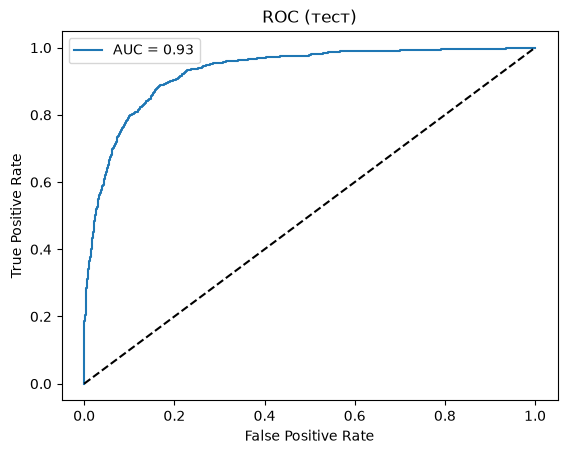

In [39]:
log_reg.fit(X_train, target_train)
test_proba = log_reg.predict_proba(X_test)[:, 1]

for name, t in [('порог 0.5', 0.5), ('выбранный порог', best_threshold)]:
    pred = (test_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(target_test, pred).ravel()
    print(f'{name} ({t:.2f}): TP={tp}, FP={fp}, FN={fn}, TN={tn}, '
          f'precision={precision_score(target_test, pred):.2f}, recall={recall_score(target_test, pred):.2f}, '
          f'стоимость={COST_FP * fp + COST_FN * fn}')
print('ROC-AUC на тесте:', round(roc_auc_score(target_test, test_proba), 3))

fpr, tpr, _ = roc_curve(target_test, test_proba)
plt.plot(fpr, tpr, label=f'AUC = {roc_auc_score(target_test, test_proba):.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC (тест)')
plt.legend()
plt.show()

На тесте ROC-AUC 0.93. При пороге 0.5 модель находит только 67% премиальных квартир, при пороге 0.30 - 83%; precision падает с 0.80 до 0.68, но суммарная стоимость ошибок снижается с 1058 до 822 (-22%). Если пропуск премиальной квартиры обходится агентству дороже (5:1), порог нужно снизить до 0.18.

## 9. Цена м² по районам (доверительный интервал)

Средняя цена м² по районам с 95% ДИ: среднее ± 1.96 · std / √n.

In [40]:
district_rows = []
for district, part in train.groupby('district'):
    mean, low, high = mean_ci(part['price_per_m2'])
    district_rows.append({'район': district, 'n': len(part), 'средняя цена м², тыс': mean / 1e3,
                          'ДИ низ': low / 1e3, 'ДИ верх': high / 1e3,
                          '± тыс': (high - mean) / 1e3})
district_ci = pd.DataFrame(district_rows).sort_values('средняя цена м², тыс', ascending=False)
district_ci.round(1)

,район,n,"средняя цена м², тыс",ДИ низ,ДИ верх,± тыс
2,esil,3549,581.200,575.800,586.700,5.500
3,nura,3948,552.900,547.800,557.900,5.100
0,almaty,4365,472.800,468.400,477.300,4.400
4,saryarka,1761,425.200,420.800,429.600,4.400
1,baikonur,886,419.200,414.000,424.300,5.100


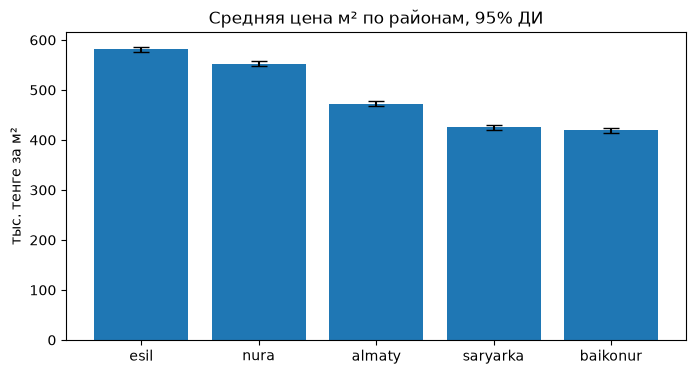

In [41]:
plt.figure(figsize=(8, 4))
plt.bar(district_ci['район'], district_ci['средняя цена м², тыс'],
        yerr=district_ci['± тыс'], capsize=6)
plt.ylabel('тыс. тенге за м²')
plt.title('Средняя цена м² по районам, 95% ДИ')
plt.show()

In [42]:
esil = train[train['district'] == 'esil']['price_per_m2']
others = train[train['district'] != 'esil']['price_per_m2']
diff = esil.mean() - others.mean()
se_diff = np.sqrt(esil.var() / len(esil) + others.var() / len(others))
print(f'Есиль дороже остальных районов на {diff / 1e3:,.0f} тыс. тенге за м² '
      f'(95% ДИ: {(diff - 1.96 * se_diff) / 1e3:,.0f} – {(diff + 1.96 * se_diff) / 1e3:,.0f} тыс.)')
print(f'Для квартиры 60 м²: {diff * 60 / 1e6:.1f} млн тенге '
      f'(ДИ: {(diff - 1.96 * se_diff) * 60 / 1e6:.1f} – {(diff + 1.96 * se_diff) * 60 / 1e6:.1f} млн)')

Есиль дороже остальных районов на 92 тыс. тенге за м² (95% ДИ: 85 – 98 тыс.)
Для квартиры 60 м²: 5.5 млн тенге (ДИ: 5.1 – 5.9 млн)


Есиль - самый дорогой район: 581 тыс. тенге за м² (95% ДИ 576-587 тыс.), на 85-98 тыс./м² дороже остальных районов. Для квартиры 60 м² это 5,1-5,9 млн тенге. Есиль, Нура и Алматы различаются значимо (интервалы не пересекаются), а интервалы Сарыарки и Байконура пересекаются - какой из них дешевле, по этим данным сказать нельзя.

Для агентства интервал означает: по другой выборке объявлений средняя цена м² в Есиле с вероятностью 95% тоже оказалась бы в пределах 576-587 тыс. Интервал узкий (±1%), поэтому эту цифру можно использовать в разговоре с клиентом. Ограничения: это цены объявлений, а не сделок; разница между районами частично объясняется тем, что в Есиле больше домов бизнес- и премиум-класса.

## 10. Границы применимости

Ошибки финальной модели на тесте по группам, которые известны до оценки.

In [43]:
test['ape'] = ape_test
test['pred'] = pred_test

test['area_group'] = pd.cut(test['area'], bins=[0, 40, 60, 90, 150, 1000],
                            labels=['до 40', '40–60', '60–90', '90–150', '150+'])
test['year_group'] = pd.cut(test['construction_year'], bins=[1900, 1990, 2005, 2015, 2030],
                            labels=['до 1990', '1990–2005', '2005–2015', '2015+'])
test['complex_known'] = np.where(test['complex_group'] == 'other', 'редкий/без ЖК', 'частый ЖК')


def error_by(column):
    table = test.groupby(column, observed=True).agg(
        n=('ape', 'count'),
        MAPE=('ape', 'mean'),
        медиана_ошибки=('ape', 'median'),
        доля_ошибок_больше_20=('ape', lambda x: np.mean(x > 20) * 100))
    return table.round(1)


for col in ['complex_class', 'area_group', 'year_group', 'district', 'segment_name', 'complex_known', 'condition', 'room_count']:
    print('===', col)
    print(error_by(col))
    print()

=== complex_class
                  n   MAPE  медиана_ошибки  доля_ошибок_больше_20
complex_class                                                    
business        623 10.400           7.000                 14.000
comfort        1650  9.800           7.400                 11.500
economy        1172  8.600           6.400                  8.300
premium         194 13.100           8.100                 24.200

=== area_group
               n   MAPE  медиана_ошибки  доля_ошибок_больше_20
area_group                                                    
до 40        776  8.600           6.500                  9.000
40–60       1170  8.600           6.800                  7.600
60–90        976  9.900           7.000                 11.900
90–150       597 11.400           8.100                 17.100
150+         120 17.200          11.900                 35.800

=== year_group
               n   MAPE  медиана_ошибки  доля_ошибок_больше_20
year_group                                        

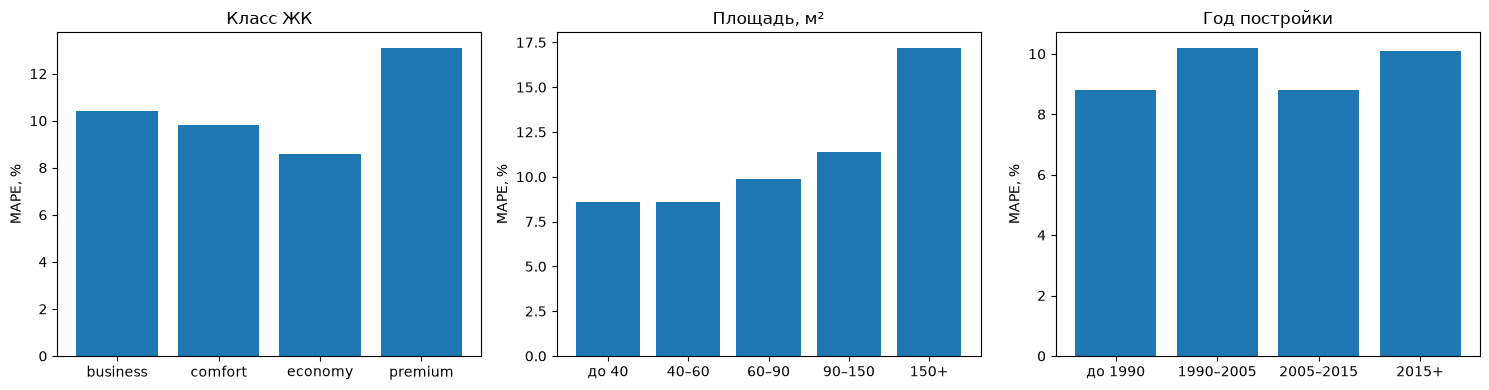

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(axes, ['complex_class', 'area_group', 'year_group'],
                          ['Класс ЖК', 'Площадь, м²', 'Год постройки']):
    t = error_by(col)
    ax.bar(t.index.astype(str), t['MAPE'])
    ax.set_title(title)
    ax.set_ylabel('MAPE, %')
plt.tight_layout()
plt.show()

In [45]:
worst = test.sort_values('ape', ascending=False).head(20)
worst[['name', 'price', 'pred', 'ape', 'complex_class', 'district', 'construction_year', 'complex_name']].round(1)

,name,price,pred,ape,complex_class,district,construction_year,complex_name
2782,"2-комнатная квартира, 50 м², 1/12 этаж",11000000,"22,157,177.300",101.400,economy,saryarka,2008,тамыз
3190,"4-комнатная квартира, 257.4 м², 4/6 этаж",100000000,"198,894,283.100",98.900,premium,nura,2014,атриум
2704,"4-комнатная квартира, 111 м², 6/9 этаж",23310000,"46,283,749.600",98.600,comfort,nura,2024,onyx comfort
938,"2-комнатная квартира, 80 м², 10/11 этаж",28000000,"49,660,484.700",77.400,business,almaty,2020,monaco residence
320,"4-комнатная квартира, 105 м², 7/9 этаж",36000000,"62,532,393.800",73.700,business,esil,2005,визит
3261,"4-комнатная квартира, 213 м², 2/6 этаж",380000000,"138,240,856.200",63.600,premium,esil,2023,royal expo apartments
999,"4-комнатная квартира, 104 м², 23/23 этаж",27000000,"43,698,469.200",61.800,comfort,baikonur,2008,москва
770,"7-комнатная квартира, 400 м², 5/12 этаж",415000000,"167,833,269.400",59.600,comfort,esil,2005,нурсая
2616,"2-комнатная квартира, 65 м², 4/10 этаж",25000000,"39,443,393.800",57.800,comfort,nura,2022,ару кала
795,"4-комнатная квартира, 125 м², 7/9 этаж",45500000,"71,172,035.400",56.400,comfort,esil,2023,лея за рекой


| Группа | MAPE | Ошибок > 20% | Причина |
|---|---|---|---|
| площадь 150+ м² | 17% | 36% | мало примеров, объекты уникальные |
| 5+ комнат | 14-41% | 36-100% | единичные объекты |
| премиум | 13,1% | 24% | цена зависит от вида, дизайна, мебели - этого нет в данных |
| сегмент «большие бизнес/премиум» | 12,6% | 22% | квартиры мало похожи друг на друга |
| черновая отделка | 11,7% | 17% | неизвестен будущий ремонт |
| редкие ЖК / без ЖК | 10,8% | 15% | модель не знает престиж конкретного дома |
| эконом, 1-2 комнаты, до 60 м² | 8,6-9,2% | 8-10% | много похожих примеров |

Для квартир больше 150 м², с 5 и более комнатами и премиум-класса прогноз модели использовать не следует: средняя ошибка 13-17% и выше, у четверти-трети объектов промах больше 20%. Таких объектов мало в данных, а их цену определяют факторы, которых в данных нет. Для них нужна ручная оценка.

Кроме того, модель не учитывает качество ремонта, вид из окна и срочность продажи. Среди худших прогнозов есть квартиры, выставленные вдвое дешевле рынка, - модель предсказывает для них рыночную цену. Модель обучена на объявлениях одного периода, при изменении рынка её нужно переобучать.

## 11. Модель для контрольной выборки

Финальную модель обучаю на всех данных (train + test), очищенных по правилам из 2.3. `predict_price(new_data)` принимает таблицу в формате `merged_df.csv` (без `price`) и возвращает прогноз цены в тенге.

In [46]:
full_raw = pd.concat([train_raw, test_raw], ignore_index=True)
full_raw['price_per_m2'] = full_raw['price'] / full_raw['area']
bad_rows = (
    (full_raw['price_per_m2'] > 3_000_000) |
    (full_raw['price_per_m2'] < 150_000) |
    (full_raw['area'] < 15) |
    (full_raw['area'] / full_raw['room_count'] < 8) |
    (full_raw['distance_to_center'] > 30) |
    (full_raw['construction_year'] < 1950) |
    (full_raw['district'] == 'Косшы р-н')
)
full = full_raw[~bad_rows].reset_index(drop=True)

full = split_coordinates(full)
district_medians = full.groupby('district')[distance_cols + ['lat', 'lon']].median()
city_medians = full[distance_cols + ['lat', 'lon']].median()
complex_counts = full['complex_name'].value_counts()
frequent_complexes = list(complex_counts[complex_counts >= 15].index)

full = prepare_features(full)
encoder = OneHotEncoder(handle_unknown='ignore')
encoder.fit(full[categorical_features])
scaler = StandardScaler()
scaler.fit(full[numeric_features])

final_model = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1,
                                    **forest_grid.best_params_)
final_model.fit(make_X(full), np.log(full['price'].values))
print('Обучено на', len(full), 'квартирах')


def predict_price(new_data):
    prepared = prepare_features(new_data)
    return np.exp(final_model.predict(make_X(prepared)))


example = raw.drop(columns=['price']).head(5)
print(pd.DataFrame({'объявление': raw['name'].head(5),
                    'цена': raw['price'].head(5),
                    'прогноз': predict_price(example).round(-3)}))

Обучено на 18139 квартирах
                                 объявление      цена        прогноз
0     3-комнатная квартира, 77 м², 1/4 этаж  33000000 33,535,000.000
1    1-комнатная квартира, 40 м², 3/14 этаж  21000000 21,681,000.000
2  1-комнатная квартира, 43.8 м², 6/18 этаж  18500000 17,634,000.000
3    3-комнатная квартира, 115 м², 5/7 этаж  51000000 47,955,000.000
4   2-комнатная квартира, 60 м², 13/14 этаж  25000000 26,882,000.000
